# Distributed BAX Emittance Optimization — A Physics and Software Tutorial

This notebook demonstrates a **local client computer** running a simulated beam-size evaluator and a **remote back-end computer** running the BAX candidate generator through `CloudpickleHTTPGenerator`. It explains the beam physics, the software roles, and the purpose of each code cell.

**Validated example:** the original experiment completed 24 executable code cells successfully. This tutorial edition retains the scientific workflow but has its saved outputs cleared; run it against a compatible back-end to validate your own setup.


## Prerequisites

Before running this experiment, prepare two Python environments:

**Local client computer**

- Install the scientific packages required by this notebook, including Xopt, `bax_algorithms`, PyTorch, and the beam simulation/evaluation dependencies.
- Use an Xopt development version that provides `CloudpickleHTTPGenerator`.
- Run JupyterLab here. The beam simulation and evaluator execute locally.

**Remote back-end computer**

- Start an Xopt HTTPGenerator-compatible service, reachable from the client.
- Install compatible Xopt, `bax_algorithms`, PyTorch, BoTorch, and GPyTorch packages.
- JupyterLab is not required on the back-end.
- Configure `XOPT_REMOTE_URL` on the client to point to this service.

**Important:** The `CloudpickleHTTPGenerator` functionality used here is part of the Xopt HTTPGenerator development work. Until that functionality is merged and released, use a compatible Xopt development branch on both computers.

**Python compatibility:** Prefer matching Python minor versions and compatible Xopt/BAX/scientific dependency versions on both computers. Cloudpickle transports configured Python objects, not an entire Python environment.

**Validation:** This example was successfully exercised with 24 executable cells before the tutorial annotations were added. The current tutorial contains 25 code cells and should be executed again after changes.


## How to read this notebook

Work through the cells from top to bottom. Each code cell has a short explanation immediately before it. The local client needs the notebook, Xopt, beam simulation, and scientific packages used to construct the generator. The remote back-end needs the HTTP service and compatible BAX/scientific dependencies. The remote container does **not** need JupyterLab or the local BeamSim evaluator.


## 1. Connect to the remote back-end computer

**Software idea:** The notebook runs on your **local client computer**. The optimization generator runs in a container on a **remote back-end computer**. `XOPT_REMOTE_URL` tells the client where to send HTTP requests. The default `http://localhost:8002` is useful when the service runs on the same computer; for a separate machine, set the variable before launching JupyterLab, for example `export XOPT_REMOTE_URL=http://<backend-host>:8002` (replace the placeholder with the real host).

**Why this cell?** Keeping the address outside the notebook makes the example portable. No beam physics happens in this cell.

In [3]:
import os

REMOTE_XOPT_URL = os.environ.get(
    "XOPT_REMOTE_URL", "http://localhost:8002"
).rstrip('/')

print(f"XOPT_REMOTE_URL environment variable: {os.environ.get('XOPT_REMOTE_URL', '<not set>')}")
print(f"Effective Xopt backend URL: {REMOTE_XOPT_URL}")

XOPT_REMOTE_URL environment variable: http://10.0.0.87:8002
Effective Xopt backend URL: http://10.0.0.87:8002


## 2. Import the software tools

- **Xopt** coordinates the optimization loop.
- **VOCS** describes what the optimizer can change and measure.
- **BaxGenerator** builds a probabilistic model and proposes informative measurements.
- **Evaluator** calls the beam-size measurement function on the local client.
- **PyTorch, NumPy, Matplotlib** provide numerical arrays, models, and plots.

The imports do **not** move the evaluator to the back-end. They make the necessary Python definitions available locally so we can construct the generator that will be serialized.

In [5]:
# Ignore all warnings
import warnings

import matplotlib.pyplot as plt

import torch

from xopt import Xopt
from xopt.vocs import VOCS
from xopt.generators.bayesian.bax_generator import BaxGenerator

from xopt.evaluator import Evaluator

import time
import numpy as np
import random

warnings.filterwarnings("ignore")

### Why use double-precision tensors?

Accelerator calculations and Gaussian-process models can be sensitive to numerical precision. This cell selects 64-bit floating-point tensors as the default for the existing example. It does **not** turn on GPU acceleration.

In [6]:
torch.set_default_tensor_type("torch.DoubleTensor")

# Notebook settings

## 3. Choose experiment settings

**Physics:** We use two input variables. One represents a tuning direction; the other (`meas_dim = 1`) is the quadrupole-scan coordinate. A quadrupole focuses the electron beam differently in the horizontal and vertical planes. Measuring beam size at several quadrupole settings helps infer emittance, a measure of the beam's spread in position and angle.

**Optimization:** We start with `n_obs_init = 10` random measurements, then request `n_iter = 10` additional steps. `n_samples` controls the number of BAX posterior samples. Fixed random seeds help reproduce the example, although distributed execution and numerical libraries can still introduce variation. `use_bmag=False` means the example's emittance objective is not multiplied by the optional mismatch factor.

In [7]:
ndim = 2  # number of input dimensions
noise = False  # whether to add noise to the ground-truth beam size function outputs
thin_lens = False
use_bmag = False
meas_dim = 1  # input dimension for measurement parameter
n_obs_init = 10  # number of random initial observations for GP model
n_samples = 3  # number of posterior samples for BAX
n_iter = 1  # number of optimization steps for Xopt to take (after acquiring random initial data)
rand_seed = 3

# random seeds for reproducibility
torch.manual_seed(rand_seed)
np.random.seed(rand_seed)  # only affects initial random observations through Xopt
random.seed(rand_seed)

# Build test function from single-quadrupole optical beam size model 
Here we define a simple ground-truth beam size function for our optimization problem, where we attempt to find the location in tuning parameter space with minimal emittance. Note that the function "test_func" used to evaluate the ground-truth beam size function takes a dictionary as input and returns a dictionary as the output.

## 4. Load the beamline model (local client)

**Physics:** The beamline configuration provides the quadrupole length (`q_len`), beam energy, and transport matrices (`rmat_x`, `rmat_y`). Transport matrices describe how beam position and angle evolve through the beamline.

**Software:** `BeamSim` and the configuration files stay on the **local client computer**. The remote back-end does not need this simulator to propose candidate settings.

In [8]:
from pyemittance.load_json_configs import load_configs
from pyemittance.simulation import BeamSim

CONFIG = load_configs("LCLS2_OTR0H04")
CONFIG["beamline_info"]

q_len = CONFIG["beamline_info"]["Lquad"]
energy = CONFIG["beamline_info"]["energy"]
rmat_x = torch.tensor(CONFIG["beamline_info"]["rMatx"]).reshape(2, 2)
rmat_y = torch.tensor(CONFIG["beamline_info"]["rMaty"]).reshape(2, 2)
print(rmat_x)
print(rmat_y)

tensor([[1.0000, 2.2000],
        [0.0000, 1.0000]])
tensor([[1.0000, 2.2000],
        [0.0000, 1.0000]])


### Build a simulated electron beam and its measurement function

`BUNCH_PARAMS0` sets the simulated beam charge, horizontal and vertical normalized emittances, Twiss parameters, energy, and particle species. The Twiss parameters describe the beam's phase-space shape.

`measure_beamsize(input_dict)` is our **local evaluator**: it accepts a dictionary of settings, asks `BeamSim` for horizontal and vertical beam sizes, applies the example's detuning/scaling model, and returns `xrms_sq` and `yrms_sq`. These are **squared beam-size observables**, not emittance itself. The `+ 50` terms are part of the example's synthetic measurement model; they are not measurements from real hardware.

The optimizer learns from these returned values. It does not remotely execute `BeamSim`.

In [9]:
BUNCH_PARAMS0 = {
    "total_charge": 50e-12,
    "norm_emit_x": 1e-6,
    "norm_emit_y": 2e-6,
    "beta_x": 10,
    "alpha_x": -1,
    "beta_y": 11,
    "alpha_y": -2,
    "energy": 80e6,
    "species": "electron",
}
sim = BeamSim(bunch_params=BUNCH_PARAMS0, beamline_info=CONFIG["beamline_info"])


# define variables functions
var_names = ["x" + str(i) for i in range(ndim)]
meas_param = var_names[meas_dim]


def measure_beamsize(input_dict):
    scale = 1.0e4
    x_tuning = torch.tensor([])
    for key in input_dict.keys():
        if key != str(meas_param):
            x_tuning = torch.cat((x_tuning, torch.tensor([input_dict[key]])))
    rms_beamsizes0 = np.array(sim.beam_size_meas(input_dict[meas_param]))
    detuning_scale = 1.0 + 1 * x_tuning.abs().sum().cpu()
    xrms, yrms = detuning_scale * rms_beamsizes0
    return {
        "xrms_sq": (float(xrms) * scale) ** 2.0 + 50,
        "yrms_sq": (float(yrms) * scale) ** 2.0 + 50,
    }  # mean-square beam sizes in mm squared

# Construct vocs

## 5. Define VOCS: the optimization contract

**VOCS** means **Variables, Objectives, Constraints, and Constants**. Here we specify the two adjustable variables and their allowed ranges, plus two observables: `xrms_sq` and `yrms_sq`. There is no direct scalar objective declared in this VOCS; the BAX algorithm uses the observables to reason about emittance.

The scan variable gets a wider range because we need measurements on both sides of the quadrupole-scan minimum. Printing the bounds is a useful sanity check before running an optimizer.

In [10]:
variables = {var_name: [-1, 0.5] for var_name in var_names}
variables[meas_param] = [
    -5,
    5,
]  # overwrite bounds for measurement parameter to capture minimum of single-quadrupole optical model

# construct vocs
vocs = VOCS(
    variables=variables,
    observables=["xrms_sq", "yrms_sq"],
)

print("variable_names =", vocs.variable_names)
print("meas_param =", "'" + meas_param + "'")
print("domain =\n", vocs.bounds)

variable_names = ['x0', 'x1']
meas_param = 'x1'
domain =
 [[-1.0, 0.5], [-5.0, 5.0]]


## 6. Define the reference emittance calculation

**Physics:** A quadrupole scan changes focusing. By evaluating beam sizes at several quadrupole strengths, `compute_emit_bmag_quad_scan` reconstructs emittance-related quantities. This helper evaluates the simulated *ground truth* for comparison with the learned model. It is **not** the function Xopt directly minimizes at every step.

**Software:** `lcls_tools` is needed here on the local client for this reference calculation. This cell loops over scan settings and computes a combined horizontal/vertical emittance metric. The optional `use_bmag` switch can include the mismatch factor.

In [11]:
from lcls_tools.common.measurements.emittance_measurement import (
    compute_emit_bmag_quad_scan,
)
from lcls_tools.common.data.model_general_calcs import bdes_to_kmod


def eval_true_emittance(x, use_bmag=False):
    emits = []
    bmags = []
    q = torch.linspace(-3, 3, 11)
    k = bdes_to_kmod(energy, q_len, q)
    k = torch.stack((k, -k))
    rmat = torch.stack((rmat_x, rmat_y))
    twiss0_x = torch.tensor([10, -1])
    twiss0_y = torch.tensor([11, -2])
    twiss0 = torch.cat((twiss0_x.reshape(1, 2), twiss0_y.reshape(1, 2)))
    for setting in x:
        bssx = []
        bssy = []
        input_dict = {
            name: float(setting[i]) for i, name in enumerate(vocs.variable_names)
        }
        for v in q.numpy():
            input_dict[meas_param] = v
            output_dict = measure_beamsize(input_dict)
            bssx += [output_dict["xrms_sq"]]
            bssy += [output_dict["yrms_sq"]]
        bss = torch.tensor([bssx, bssy])

        # compute emittance
        rv = compute_emit_bmag_quad_scan(
            k.numpy(),
            bss.detach().numpy(),
            q_len,
            rmat.numpy(),
            twiss0.numpy(),
            thin_lens=thin_lens,
            maxiter=100,
        )

        emit = torch.from_numpy(rv["emittance"])
        bmag = torch.from_numpy(rv["bmag"])
        emits += [torch.sqrt(emit[0, 0] * emit[1, 0])]
        bmags += [torch.sqrt(bmag[0].min() * bmag[1].min())]
    res = torch.tensor(emits)
    if use_bmag:
        res *= torch.tensor(bmags)
    return res


eval_true_emittance(torch.zeros(1, ndim), use_bmag=use_bmag)

tensor([9.7553])

### Plot the reference curve

This plot sweeps the tuning variable while holding the scan coordinate at its initialized value. It helps us understand where the simulated emittance is small **before** examining the optimizer's predictions. In a real machine, we generally would not know this ground-truth curve in advance.

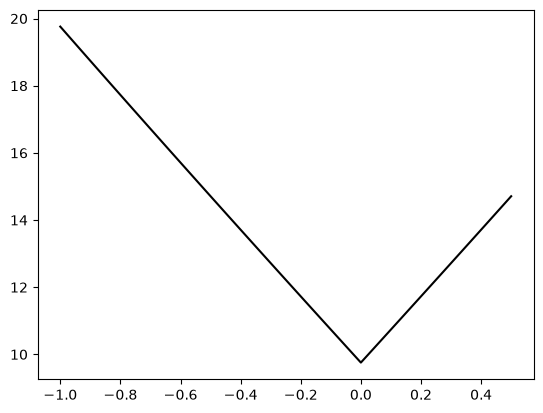

In [12]:
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
plt.plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")

# Prepare generator options.
In this example, we use a specialty covariance module (Matern x Quadratic kernel) for our beam size model.

## 7. Describe how BAX learns from beam-size measurements

**Physics:** Beam size varies smoothly with tuning settings but has a characteristic dependence on quadrupole-scan strength.

**Software:** A **Gaussian process (GP)** is a probabilistic model: it predicts beam size and expresses uncertainty where data are sparse. The custom kernel combines a Matérn term for tuning dimensions with a quadratic polynomial term for the scan dimension. Separate kernels model `xrms_sq` and `yrms_sq`.

This cell configures the model constructor; it does not yet fit a model or communicate with the remote back-end.

In [13]:
from gpytorch.kernels import MaternKernel, PolynomialKernel, ScaleKernel

from xopt.generators.bayesian.models.standard import StandardModelConstructor

# prepare custom covariance module
tuning_dims = list(range(vocs.n_variables))
tuning_dims.remove(meas_dim)
covar_module_x = MaternKernel(
    ard_num_dims=len(tuning_dims), active_dims=tuning_dims, lengthscale_prior=None
) * PolynomialKernel(power=2, active_dims=[meas_dim])

scaled_covar_module_x = ScaleKernel(
    covar_module_x
)  # , outputscale_prior=GammaPrior(2.0, 0.15))
covar_module_y = MaternKernel(
    ard_num_dims=len(tuning_dims), active_dims=tuning_dims, lengthscale_prior=None
) * PolynomialKernel(power=2, active_dims=[meas_dim])
scaled_covar_module_y = ScaleKernel(
    covar_module_y
)  # , outputscale_prior=GammaPrior(2.0, 0.15))

# prepare options for Xopt generator
covar_module_dict = {"xrms_sq": scaled_covar_module_x, "yrms_sq": scaled_covar_module_y}

model_constructor = StandardModelConstructor(
    covar_modules=covar_module_dict, use_low_noise_prior=True
)

### Select an optimizer for candidate search

`LBFGSOptimizer` is used by the Xopt/BAX generator when optimizing its acquisition function—roughly, choosing which new measurement would be most useful. This is different from the physics-side `DifferentialEvolution` optimizer used inside the emittance algorithm.

In [14]:
from xopt.numerical_optimizer import LBFGSOptimizer

numerical_optimizer = LBFGSOptimizer(n_restarts=10, max_time=2)
# numerical_optimizer = GridOptimizer()

# Construct generator, evaluator, Xopt objects

## 8. Construct the BAX algorithm and remote wrapper

**Physics:** `PathwiseMinimizeEmittance` uses modeled horizontal and vertical beam-size scans, beam energy, transport matrices, and Twiss parameters to infer promising emittance-minimizing settings. `DifferentialEvolution` is used within that algorithm.

**Software:** `BaxGenerator` is the scientific generator, configured with `use_cuda=True` for remote GPU computation. `CloudpickleHTTPGenerator` is an Xopt-compatible proxy that transfers the configured generator to the **Fedora GPU back-end**. The local `Evaluator` continues to call `measure_beamsize` on **lepton**. `Xopt` coordinates the two sides.

### Why does `vocs` appear three times?

The BAX generator, HTTP wrapper, and Xopt controller each require the same Variables, Objectives, Constraints, and Constants (VOCS) contract. These are three uses of the same configuration, **not** three network requests per iteration.

### Why install BAX on the back-end if we use Cloudpickle?

Cloudpickle serializes Python objects, but not the installed scientific packages, compiled PyTorch libraries, or GPU drivers. Fedora must have compatible Xopt, BAX, PyTorch, BoTorch, and GPyTorch installations. Lepton needs the packages used to construct the generator, evaluate beam sizes, and display results.

**GPU validation:** Candidate generation and model fitting are configured for Fedora's GPU (`use_cuda=True`). The early, pre-optimization plots below use a **separate CPU-only diagnostic model** because the remote generator has not yet trained its model. After the adaptive loop, we instead retrieve a **CPU-safe snapshot of the actual fitted remote generator** for visualization. The snapshot does not move or alter the live GPU model.


In [15]:
from bax_algorithms.emittance import PathwiseMinimizeEmittance
from bax_algorithms.pathwise.optimize import DifferentialEvolution

# Prepare Algorithm
algo_kwargs = {
    "x_key": "xrms_sq",
    "y_key": "yrms_sq",
    "energy": energy,
    "q_len": q_len,
    "rmat_x": rmat_x,
    "rmat_y": rmat_y,
    "twiss0_x": torch.tensor([10.0, -1.0]),
    "twiss0_y": torch.tensor([11.0, -2.0]),
    "n_samples": n_samples,
    "meas_dim": meas_dim,
    "n_steps_measurement_param": 11,
    "use_bmag": use_bmag,
    "observable_names_ordered": ["xrms_sq", "yrms_sq"],
    "optimizer": DifferentialEvolution(minimize=True, maxiter=10, verbose=True),
    # 'maxiter_fit': 10,
    "crop_scans": False,
}
algo = PathwiseMinimizeEmittance(**algo_kwargs)
# algo = GridMinimizeEmitBmag(**algo_kwargs)
# algo = ScipyMinimizeEmittanceXY(**algo_kwargs)

# construct BAX generator
generator = BaxGenerator(
    vocs=vocs,
    gp_constructor=model_constructor,
    numerical_optimizer=numerical_optimizer,
    algorithm=algo,
    use_cuda=True,
)

generator.gp_constructor.use_low_noise_prior = True
# Wrap the validated BAX generator for remote execution on the remote back-end computer.
from xopt.generators.remote.cloudpickle import CloudpickleHTTPGenerator

remote_generator = CloudpickleHTTPGenerator(
    vocs=vocs,
    generator=generator,
    base_url=REMOTE_XOPT_URL,
    timeout=300.0,
    state_timeout=300.0,
)

# construct evaluator
evaluator = Evaluator(function=measure_beamsize)

# construct Xopt optimizer
X = Xopt(evaluator=evaluator, generator=remote_generator, vocs=vocs)

# Optimize

## 9. Collect initial measurements

Before a GP can learn a useful model, it needs data. `X.random_evaluate(n_obs_init)` selects random settings within the VOCS bounds and evaluates the **local** `measure_beamsize` function. These observations become training data for subsequent BAX candidate generation. Random initialization is not the same as the ten adaptive optimization steps below.

In [16]:
# call X.random_evaluate() to generate random initial points and evaluate on test_func
X.random_evaluate(n_obs_init)

,x0,x1,xrms_sq,yrms_sq,xopt_runtime,xopt_error
0,-0.326197,4.701238,128.500827,826.099531,0.000547,False
1,-0.562222,0.431668,62.502374,161.927624,0.000310,False
2,0.063643,-1.491440,96.277857,51.063035,0.000219,False
3,-0.266241,2.215127,54.503387,304.541087,0.000194,False
4,-0.839420,-1.762549,215.441820,52.179909,0.000175,False
5,-0.844440,-0.908628,139.266843,72.189578,0.000180,False
6,0.311622,4.760181,129.512278,823.890367,0.000171,False
7,0.189136,-0.588541,77.744241,67.695749,0.000161,False
8,0.422799,2.407476,58.564205,404.797215,0.000161,False
9,-0.161215,0.848988,52.714173,138.889575,0.000158,False


### Choose a reference point for plots

Visualization helpers often show one or two variables while holding the others at a reference value. This dictionary uses zero for each variable. It is a **plotting reference**, not a newly measured point or a machine command.

In [17]:
reference_point = {var: 0.0 for var in vocs.variable_names}
reference_point

{'x0': 0.0, 'x1': 0.0}

## 10. Visualize the initial observations using a CPU diagnostic model

At this point we have collected random measurements, but have **not** yet called the remote BAX candidate generator. Consequently, there is no trained remote GP to retrieve.

For these *initial* plots only, we fit an independent **CPU-only diagnostic copy** of the configured BAX generator using the initial observations. This model runs on **lepton** and is not the same object as the generator on Fedora. Once the adaptive optimization has run, we will stop using this diagnostic copy and plot a CPU-safe snapshot of the **actual remote fitted model** instead.


In [18]:
# Initial-observation visualization ONLY: fit an independent CPU diagnostic model.
# The live BAX optimization still runs on Fedora with use_cuda=True.
# Do not use this helper to inspect the model after remote optimization.
import copy

def make_initial_diagnostic_generator():
    if X.data is None or len(X.data) == 0:
        raise RuntimeError("Collect initial observations before plotting")

    # Copy the local generator configuration, not the running remote session.
    diagnostic = copy.deepcopy(generator)
    diagnostic.use_cuda = False  # Lepton has no CUDA GPU.
    diagnostic.data = X.data.copy(deep=True)
    diagnostic.train_model()
    print(f"Initial CPU diagnostic model trained on lepton: {len(diagnostic.data)} observations")
    return diagnostic


### Plot the initial Gaussian-process diagnostic model

These plots show predictions from the **independently fitted CPU diagnostic model** based on the initial random measurements. They are not snapshots of Fedora's fitted GPU model. `show_acquisition=False` displays the GP prediction rather than the acquisition function.


Initial CPU diagnostic model trained on lepton: 10 observations
Beginning BAX virtual optimization.
BAX virtual optimization took: 2.8235909938812256 seconds.
Beginning BAX virtual optimization.
BAX virtual optimization took: 2.846208095550537 seconds.


(<Figure size 600x400 with 2 Axes>,
 array([[<Axes: ylabel='xrms_sq'>],
        [<Axes: xlabel='x1', ylabel='yrms_sq'>]], dtype=object))

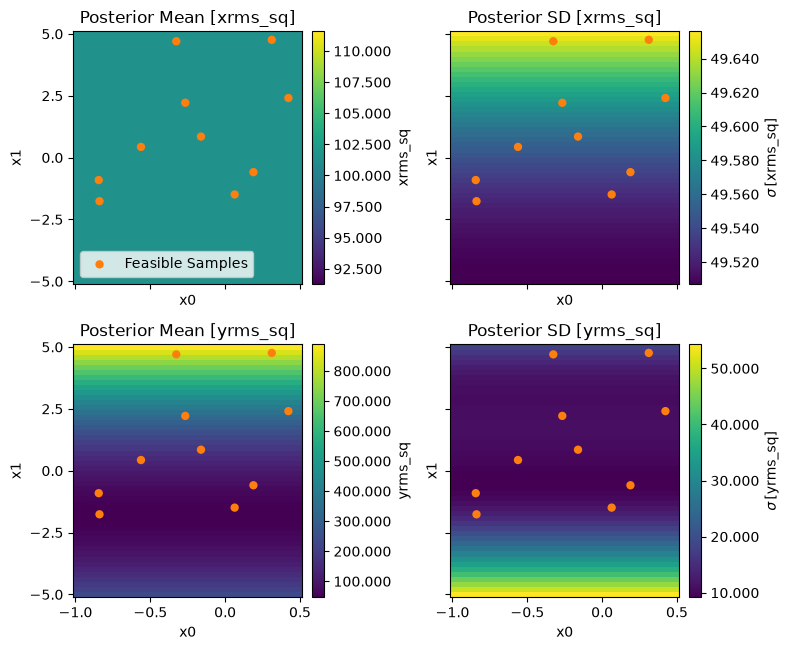

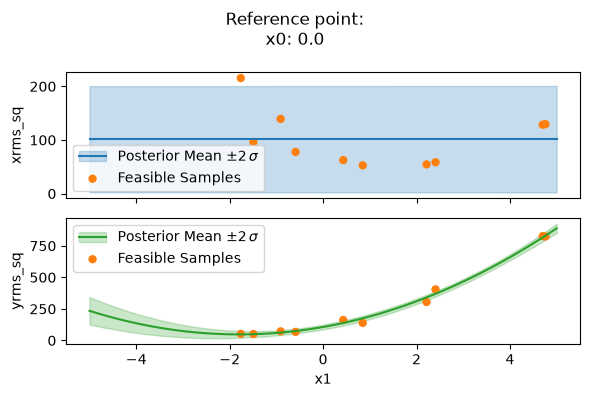

In [19]:
from xopt.generators.bayesian.visualize import visualize_generator_model

viz_generator = make_initial_diagnostic_generator()
visualize_generator_model(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    show_acquisition=False,
)
visualize_generator_model(
    viz_generator,
    variable_names=["x1"],
    reference_point=reference_point,
    show_acquisition=False,
)


### Plot BAX virtual-measurement results before adaptive steps

BAX uses plausible GP predictions to reason about virtual measurements and derived quantities such as emittance and mismatch (`bmag`). Here these are **diagnostics of the initial CPU model**, not new measurements and not the later GPU-trained remote model.


4.921849489212036


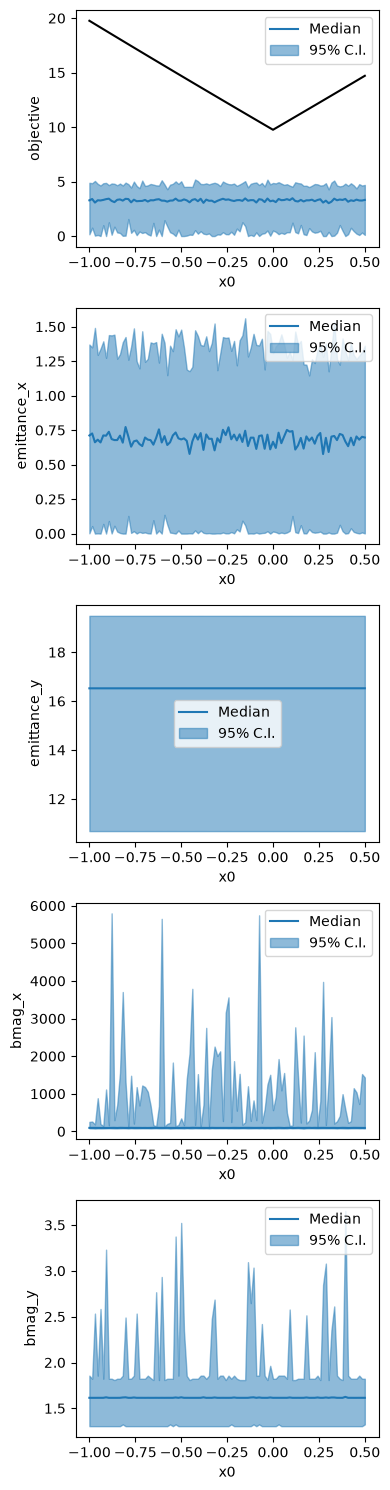

In [20]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0"],
    reference_point=reference_point,
    n_grid=100,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
ax[0].plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")
# plt.ylim(top=0.01)

### Estimate a promising tuning point from the initial diagnostic model

`get_bax_mean_prediction` estimates a favorable tuning setting using the **initial CPU diagnostic model**. The result is a model-based prediction, not a measured optimum. Later we repeat this calculation with the retrieved remote model.


In [21]:
from bax_algorithms.utils import get_bax_mean_prediction, tuning_input_tensor_to_dict

mean_optimizer = DifferentialEvolution(
    minimize=True, popsize=100, maxiter=100, verbose=True
)
x_tuning = get_bax_mean_prediction(viz_generator, mean_optimizer)
x_tuning_dict = tuning_input_tensor_to_dict(viz_generator, x_tuning)
print(x_tuning)
print(x_tuning_dict)

Beginning BAX virtual optimization.
BAX virtual optimization took: 1.1725835800170898 seconds.
tensor([[-0.2248]])
{'x0': -0.2248174670059016}


## 11. Run the distributed GPU optimization loop

Each `X.step()` requests a candidate from the **Fedora HTTP back-end**, where BAX is configured to train and generate on the GPU (`use_cuda=True`). The candidate is evaluated by the **local beam-size function on lepton**; Xopt records the new observation and sends updated data on subsequent requests.

The timer measures **end-to-end step duration**, including communication, GPU-side model work, and local evaluation; it is not a pure GPU benchmark. This experiment runs `n_iter` adaptive steps after the initial random measurements.


In [22]:
# Distributed BAX: GPU model fitting/candidate generation on Fedora;
# BeamSim evaluation and Jupyter visualization on CPU-only lepton.
remote_step_times = []
for i in range(n_iter):
    start = time.time()
    X.step()
    elapsed = time.time() - start
    remote_step_times.append(elapsed)
    print(f"Remote step {i + 1}/{n_iter}: {elapsed:.2f}s; observations={len(X.data)}")


Remote step 1/1: 28.47s; observations=11


### Check that the distributed experiment finished

The assertions verify the HTTP proxy, endpoint, observation count, and recorded evaluation errors. Successful completion confirms the configured distributed workflow ran; it does **not**, by itself, independently measure GPU utilization or establish a physical global optimum. GPU availability and the CPU-safe snapshot mechanism were verified separately on Fedora.


In [23]:
# Verify the completed distributed optimization experiment.
expected = n_obs_init + n_iter
actual = len(X.data)
print("Generator:", type(X.generator).__name__)
print("Endpoint:", X.generator.base_url)
print("Observations:", actual)
print(X.data.tail(3))

assert type(X.generator).__name__ == "CloudpickleHTTPGenerator"
assert X.generator.base_url.rstrip("/") == REMOTE_XOPT_URL.rstrip("/")
assert actual == expected, f"Expected {expected} observations; got {actual}"
if "xopt_error" in X.data.columns:
    assert not X.data["xopt_error"].fillna(False).astype(bool).any(), "Xopt evaluation errors detected"
print(f"Remote emittance full-run verification: PASS ({n_iter} remote steps)")


Generator: CloudpickleHTTPGenerator
Endpoint: http://10.0.0.87:8002
Observations: 11
          x0        x1     xrms_sq     yrms_sq  xopt_runtime  xopt_error
8   0.422799  2.407476   58.564205  404.797215      0.000161       False
9  -0.161215  0.848988   52.714173  138.889575      0.000158       False
10 -0.123324 -4.363715  258.529026  136.086232      0.000866       False
Remote emittance full-run verification: PASS (1 remote steps)


## 12. Retrieve the fitted Fedora GPU model for visualization

After the adaptive steps, the **remote BAX generator has trained its model** while producing candidates. We now call `X.generator.pull()` to retrieve a **CPU-safe snapshot of that fitted generator** through the HTTP state endpoint.

The Fedora service exports a separate snapshot with CUDA tensors mapped to CPU, while keeping the live generator and its tensors on the GPU. The returned object is suitable for visualization and model-based predictions on **CPU-only lepton**. **Do not call `X.generator.train_model()` here**: that is not a request to train the live Fedora generator, and retraining a local mirror would defeat the purpose of inspecting the remote fitted model.


In [24]:
# Pull the actual remote fitted BAX generator, serialized with tensors on CPU.
# This does not retrain the model or modify the live Fedora GPU session.
start = time.time()
viz_generator = X.generator.pull()
if viz_generator is None:
    raise RuntimeError("Remote state pull returned no generator")
if getattr(viz_generator, "model", None) is None:
    raise RuntimeError("Remote BAX generator has no fitted model; check the adaptive steps")

# Verify the retrieved GP can be used on a CPU-only notebook host.
model_parameters = list(viz_generator.model.parameters())
if model_parameters:
    model_device = model_parameters[0].device
    if model_device.type != "cpu":
        raise RuntimeError(f"Expected a CPU-safe model snapshot, got {model_device}")
    print("Retrieved remote fitted model device:", model_device)
else:
    print("Retrieved remote fitted model (no model parameters to inspect)")
print(f"Remote fitted model retrieved in {time.time() - start:.2f}s")


Retrieved remote fitted model device: cpu
Remote fitted model retrieved in 0.21s


### Visualize the GPU-trained model on lepton

These plots now use `viz_generator`, a **CPU-safe snapshot of the fitted Fedora BAX generator** retrieved in the preceding cell. No local retraining occurs. The remote optimization session remains on Fedora with its live GPU model intact.


Beginning BAX virtual optimization.
BAX virtual optimization took: 3.0794124603271484 seconds.
Beginning BAX virtual optimization.
BAX virtual optimization took: 3.323255777359009 seconds.


(<Figure size 600x400 with 2 Axes>,
 array([[<Axes: ylabel='xrms_sq'>],
        [<Axes: xlabel='x1', ylabel='yrms_sq'>]], dtype=object))

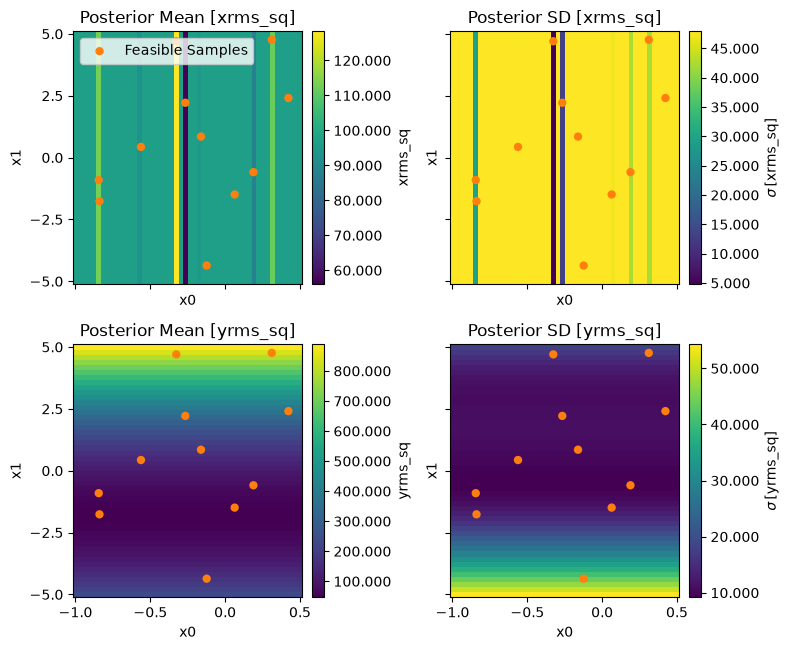

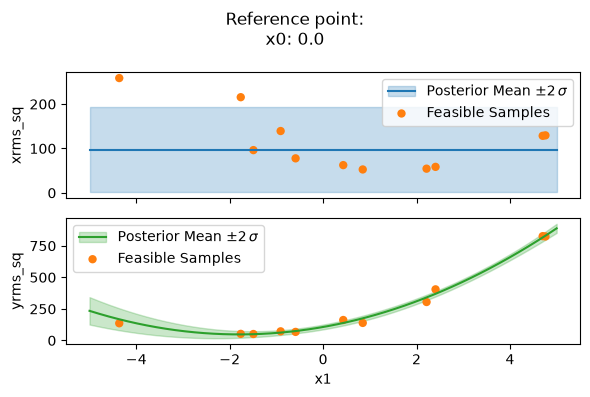

In [26]:
from xopt.generators.bayesian.visualize import visualize_generator_model

# Plot the already-fitted remote model snapshot; do not retrain locally.
visualize_generator_model(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    show_acquisition=False,
)
visualize_generator_model(
    viz_generator,
    variable_names=["x1"],
    reference_point=reference_point,
    show_acquisition=False,
)


### Inspect updated emittance predictions along one tuning direction

The virtual-measurement visualization below uses the **CPU snapshot of the Fedora-trained model** to predict emittance-related quantities. It is model-based analysis, not a fresh BeamSim measurement.


4.352365016937256


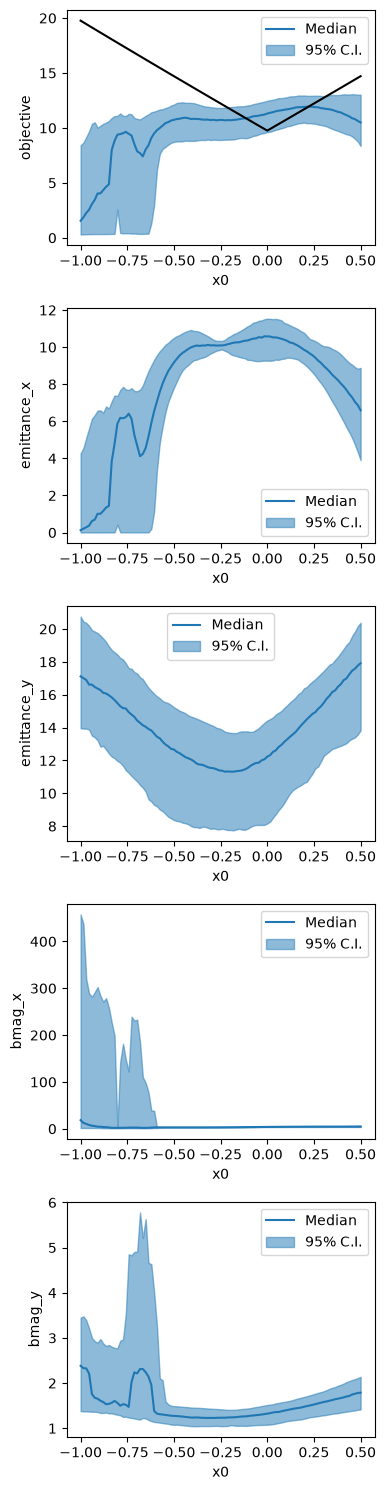

In [27]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0"],
    reference_point=reference_point,
    n_grid=100,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
ax[0].plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")

### Inspect the two-dimensional emittance landscape

This plot explores the two-variable landscape predicted by the **retrieved remote fitted model**. All plotting runs locally on lepton using the CPU-safe snapshot; the live GPU model on Fedora is unchanged.


5.102600812911987


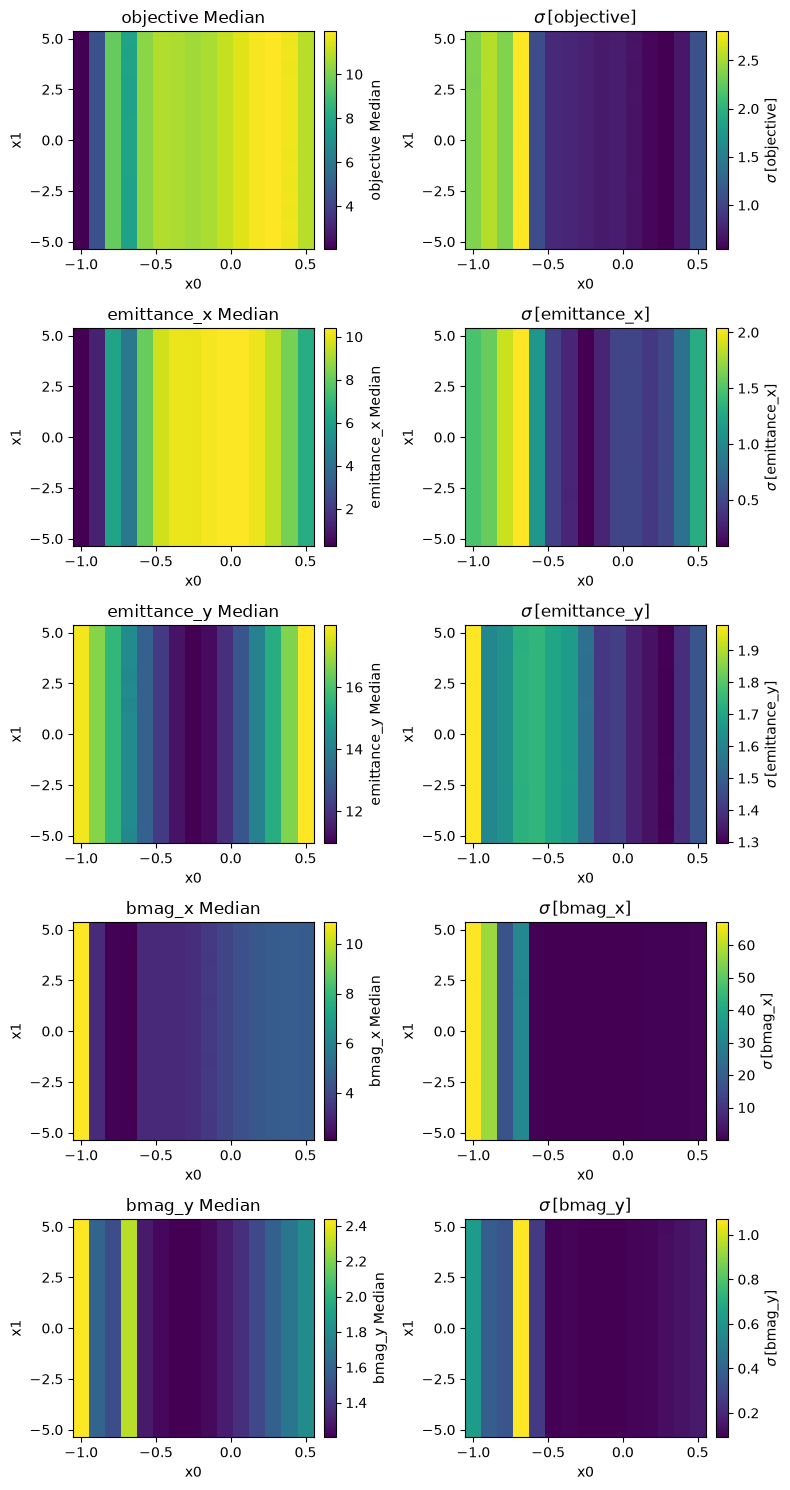

In [28]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    n_grid=15,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)

### Report the final predicted tuning setting

Using the **retrieved GPU-trained model snapshot**, we estimate a final promising tuning point and print its variable-name mapping. This is a prediction from the fitted model, not proof of a measured global minimum.


In [29]:
x_tuning = get_bax_mean_prediction(viz_generator, mean_optimizer)
x_tuning_dict = tuning_input_tensor_to_dict(viz_generator, x_tuning)
print(x_tuning)
print(x_tuning_dict)

Beginning BAX virtual optimization.
BAX virtual optimization took: 13.014083862304688 seconds.
tensor([[-0.8847]])
{'x0': -0.8847189096917909}
